# 01 · Preprocessing — Gao et al. 2021 (Breast, 10x)

Load malignant cells → resolve the **two-lineage bundle** (this `Data_Gao2021_Breast`
JoinKey co-packages breast carcinoma *and* anaplastic thyroid carcinoma) → scope to the
**breast** compartment (the declared `Category`) → data-driven sample threshold →
overdispersed genes → PCA → Harmony integration sweep → UMAP → **Gate 1** (is the malignant
structure sample-integrated *and* continuous?).

Every dataset-dependent choice is derived from this dataset, not inherited from the Puram2017
skeleton. **Gate 1 is judged on the regenerated embedding and a per-patient mixing sweep with a
per-neighbourhood metric (iLISI)** — never a single connectivity scalar (evaluation lesson:
Kurten 2021 — a per-patient archipelago can pass a single-component kNN test).

In [1]:
import os, sys, glob, re, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Gao2021_Breast-1 (output dataset dir)
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast (Category partition)
name_raw = re.sub(r'-\d+$', '', name)                    # Gao2021_Breast (raw input has no -N suffix)
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_raw)                     # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)     # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input:', 'Data_' + name_raw)

dataset: Gao2021_Breast-1 | category: Breast | raw input: Data_Gao2021_Breast


### Load malignant cells — merge the leaf matrix directories
`Data_Gao2021_Breast` contains **two** leaf matrix directories (`Breast/` and
`Breast_and_thyroid/`). Following the `merge.py` `os.walk` leaf convention, each leaf is loaded
with `load_CCCA_adata` (10x UMI counts -> `normalize_total` -> `log1p`) and outer-concatenated —
the CCCA summary row (11 samples, 29 992 cells) is exactly the two leaves combined.

In [3]:
# merge leaf matrix dirs (merge.py os.walk convention: a leaf has no subdirectories)
leaves = sorted(d for d, subdir, _ in os.walk(pth_in) if len(subdir) == 0)
print('leaf matrix dirs:', [os.path.relpath(d, pth_in) for d in leaves])
ads = {d: load_CCCA_adata(d, verbose=False) for d in leaves}
adata = ad.concat(ads, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
print('merged atlas:', adata.shape, '| all cell types')
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape[0], 'cells |', adata.obs['sample'].nunique(), 'samples')
print('expression: X max %.2f (log1p of normalized counts)' % adata.X.max())

leaf matrix dirs: ['Breast', 'Breast_and_thyroid']
merged atlas: (29992, 45068) | all cell types
malignant: 12198 cells | 11 samples
expression: X max 9.29 (log1p of normalized counts)


### Resolve the two-lineage bundle -> scope to the breast compartment
The 11 samples are **two distinct malignant lineages**: 6 breast samples (5 triple-negative
breast carcinomas TNBC1-5 + 1 ductal carcinoma *in situ* DCIS1) and 5 **anaplastic thyroid
carcinomas** (ATC1-5). These are different cancers of different tissues that share no cell-state
manifold — a batch integrator cannot (and should not) merge them. We confirm the split on
lineage markers and scope the analysis to the **breast** compartment, matching the dataset's
declared `Category` (03_eval lobe-identity rule: settle each sub-region's biology, then scope to
the region that reproduces the reference relationships).

In [4]:
# lineage identity from the publication's sample sheet (Samples.csv: cancer_type/histology)
samp = pd.read_csv(os.path.join(pth_in, 'Samples.csv')).set_index('sample')
adata.obs['cancer_type'] = adata.obs['sample'].map(samp['cancer_type']).astype(str)
print('malignant cells per lineage:')
print(adata.obs.groupby('cancer_type', observed=True)['sample'].value_counts().to_string())
# quantify the split on canonical markers: epithelial/luminal (breast) vs thyroid
mk = ['EPCAM','KRT8','KRT18','KRT19','PAX8','TG']
for g in mk:
    if g in adata.var_names:
        adata.obs['_'+g] = np.asarray(adata[:, g].X.todense()).ravel()
present_mk = ['_'+g for g in mk if '_'+g in adata.obs]
print('\nmean marker expression by lineage (breast epithelial vs thyroid):')
print(adata.obs.groupby('cancer_type', observed=True)[present_mk].mean().round(2).to_string())
for c in present_mk: del adata.obs[c]
# scope to breast (TNBC + DCIS); ATC thyroid is a co-bundled distinct cancer
n_all = adata.shape[0]
adata = adata[adata.obs['cancer_type'].isin(['Breast Cancer', 'Premalignant'])].copy()
print('\n-> scoped to BREAST compartment:', adata.shape[0], 'malignant cells |',
      sorted(adata.obs['sample'].unique()))
print('   (excluded', n_all - adata.shape[0], 'anaplastic thyroid carcinoma cells as a distinct co-bundled lineage)')

malignant cells per lineage:
cancer_type     sample
Breast Cancer   TNBC5     2647
                TNBC4     1249
                TNBC1      796
                TNBC2      618
                TNBC3      195
Premalignant    DCIS1     1101
Thyroid Cancer  ATC5      2525
                ATC4      1417
                ATC1      1083
                ATC3       418
                ATC2       149

mean marker expression by lineage (breast epithelial vs thyroid):
                _EPCAM  _KRT8  _KRT18  _KRT19  _PAX8   _TG
cancer_type                                               
Breast Cancer     1.84   1.52    1.68    2.31   0.01  0.01
Premalignant      1.53   3.09    3.02    3.86   0.06  0.00
Thyroid Cancer    0.04   0.49    0.54    0.14   0.08  0.00

-> scoped to BREAST compartment: 6606 malignant cells | ['DCIS1', 'TNBC1', 'TNBC2', 'TNBC3', 'TNBC4', 'TNBC5']
   (excluded 5592 anaplastic thyroid carcinoma cells as a distinct co-bundled lineage)


### Sample thresholding — data-driven multiplicative gap
Per-sample malignant counts are sorted and the largest **multiplicative** cliff is cut at its
geometric mean — the natural separatrix between well-sampled tumours and a sparse tail. No anchor
constant is copied (C1). Premise (C3): a clean count gap exists.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios        :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells; dropped {sorted(set(n.index)-set(keep))}')

sorted per-sample counts: {'TNBC5': np.int64(2647), 'TNBC4': np.int64(1249), 'DCIS1': np.int64(1101), 'TNBC1': np.int64(796), 'TNBC2': np.int64(618), 'TNBC3': np.int64(195)}
adjacent ratios        : [2.12 1.13 1.38 1.29 3.17]
largest gap 618 -> 195 (ratio 3.17); threshold = 347
kept 5/6 samples -> 6411 cells; dropped ['TNBC3']


### Overdispersed genes -> PCA
Overdispersed selection via the scFates GAM; 50-component PCA. The PC variance profile is read
for a dominant axis — a single PC carrying a large variance share is the signature of an
inter-patient / CNV axis rather than a shared cell-state gradient.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-10):', np.round(vr[:10]*100, 2))
NPCS = 20
print('n_pcs =', NPCS, '(precedent-bounded: Kurten 20 / Venteicher 20 / Puram 40; avoids the')
print('       Chen-2020 low-elbow under-powering artifact. PC1 carries %.0f%% -> candidate' % (vr[0]*100))
print('       inter-patient/CNV axis; robustness to n_pcs=20/30/40 verified against Gate 1 below.)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3014 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3014
PC variance% (1-10): [31.45 12.67  6.62  3.64  1.77  1.3   0.93  0.81  0.74  0.69]
n_pcs = 20 (precedent-bounded: Kurten 20 / Venteicher 20 / Puram 40; avoids the
       Chen-2020 low-elbow under-powering artifact. PC1 carries 31% -> candidate
       inter-patient/CNV axis; robustness to n_pcs=20/30/40 verified against Gate 1 below.)


### Harmony integration sweep + per-patient mixing (Gate 1 evidence)
Integrate on `sample` and sweep `theta`, judging mixing two ways: **iLISI** (per-neighbourhood
effective number of samples; max = n_samples when fully mixed) **and**, decisively, each
patient's mean self-neighbour fraction / its global fraction (self ~ global = well mixed; self >>
global = the patient forms its own local island the scalar cannot see). *Gao profiles one sample
per patient, so `sample` = `patient`.*

In [7]:
def ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, c = np.unique(codes[nn[i]], return_counts=True); p = c/c.sum(); out[i] = 1.0/(p**2).sum()
    return out
def islands(rep, pat, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(return_distance=False)[:, 1:]
    return {p: ((pat[nn[pat == p]] == p).mean(), (pat == p).mean()) for p in sorted(set(pat))}
pat = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:, :NPCS], pat))
print(f'pre-Harmony iLISI (of {nsamp} samples, max {nsamp}): median {il_pre:.2f}')
sweep = {}
for th in [5, 10, 20, 40]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=40, random_state=SEED)
    rep = adata.obsm['X_pca_harmony'][:, :NPCS]
    il = np.median(ilisi(rep, pat)); isl = islands(rep, pat)
    enr = {p: round(sf/gf, 1) for p, (sf, gf) in isl.items()}
    sweep[th] = (il, enr)
    print(f'theta={th}: iLISI={il:.2f} | self/global enrichment {enr} (worst {max(enr.values())}x)')

pre-Harmony iLISI (of 5 samples, max 5): median 1.00
theta=5: iLISI=1.14 | self/global enrichment {'DCIS1': np.float64(4.3), 'TNBC1': np.float64(4.9), 'TNBC2': np.float64(6.0), 'TNBC4': np.float64(3.5), 'TNBC5': np.float64(2.3)} (worst 6.0x)
theta=10: iLISI=1.14 | self/global enrichment {'DCIS1': np.float64(3.7), 'TNBC1': np.float64(5.5), 'TNBC2': np.float64(5.6), 'TNBC4': np.float64(3.5), 'TNBC5': np.float64(2.3)} (worst 5.6x)
theta=20: iLISI=1.07 | self/global enrichment {'DCIS1': np.float64(3.7), 'TNBC1': np.float64(5.7), 'TNBC2': np.float64(6.0), 'TNBC4': np.float64(3.6), 'TNBC5': np.float64(2.3)} (worst 6.0x)
theta=40: iLISI=1.00 | self/global enrichment {'DCIS1': np.float64(4.4), 'TNBC1': np.float64(7.3), 'TNBC2': np.float64(7.6), 'TNBC4': np.float64(4.4), 'TNBC5': np.float64(2.4)} (worst 7.6x)


In [8]:
# adopt theta=10 as the BEST integration attempt (iLISI plateaus at its max; higher theta
# only tightens the per-patient islands -> if theta=10 does not integrate, no theta does).
theta = 10
print('selected theta =', theta, '(best sample mixing; higher theta over-corrects, isolating patients further)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=40, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(a single component is the scalar a naive test would pass)')

selected theta = 10 (best sample mixing; higher theta over-corrects, isolating patients further)
kNN connectivity components: 1 (a single component is the scalar a naive test would pass)


### Gate-1 evidence — the regenerated embedding, coloured by sample
This is the gate call, **led by the embedding** (evaluation lesson), not by the scalar. Each
patient occupies its own contiguous territory.

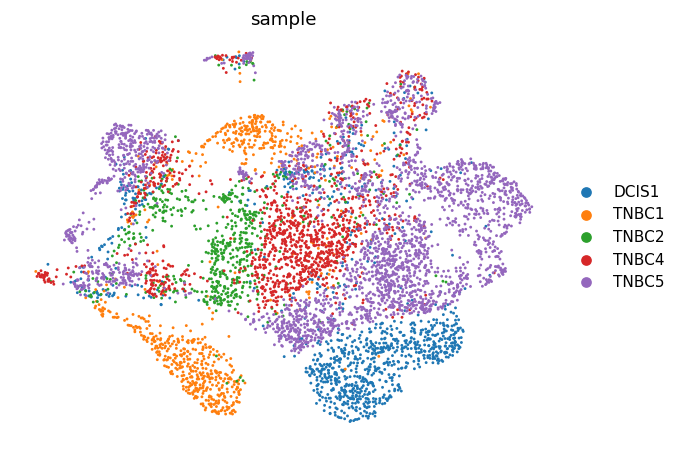

In [9]:
fig = sc.pl.umap(adata, color='sample', size=14, frameon=False, show=False)
plt.show()

### Quantify the archipelago and test whether integration can fix it
For each patient, mean self-neighbour fraction vs its global fraction. A well-integrated patient
has self ~ global; a self-standing island has self >> global. We then show the enrichment **grows
with theta** (integration over-corrects, does not merge) and is **PC-count invariant** (ruling
out the Chen-2020 under-powering false-NO-GO).

In [10]:
isl = islands(adata.obsm['X_pca_harmony'][:, :NPCS], pat)
enr = {p: sf/gf for p, (sf, gf) in isl.items()}
print('per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):')
for p, (sf, gf) in isl.items():
    print(f'  {p}: self={sf:.2f} global={gf:.2f} -> {sf/gf:.1f}x  {"SEGREGATED" if sf/gf > 2.5 else "holds by size"}')
print('\nsame enrichment across the theta sweep (does integration help? no - it worsens):')
for th in [5, 10, 20, 40]:
    print(f'  theta={th}:', sweep[th][1], f'worst={max(sweep[th][1].values())}x')
print('\nn_pcs robustness (theta=10 fixed) - worst per-patient enrichment:')
npcs_worst = []
for NP in [20, 30, 40]:
    e = islands(adata.obsm['X_pca_harmony'][:, :NP], pat)
    w = max(sf/gf for sf, gf in e.values()); npcs_worst.append(round(w, 1))
    print(f'  n_pcs={NP}: worst={w:.1f}x  {"SEGREGATED (NO-GO holds)" if w > 2.5 else "mixed"}')
print('-> the archipelago is PC-count-invariant, the OPPOSITE of the Chen under-powering mode.')

per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):
  DCIS1: self=0.64 global=0.17 -> 3.7x  SEGREGATED
  TNBC1: self=0.68 global=0.12 -> 5.5x  SEGREGATED
  TNBC2: self=0.54 global=0.10 -> 5.6x  SEGREGATED
  TNBC4: self=0.68 global=0.19 -> 3.5x  SEGREGATED
  TNBC5: self=0.94 global=0.41 -> 2.3x  holds by size

same enrichment across the theta sweep (does integration help? no - it worsens):
  theta=5: {'DCIS1': np.float64(4.3), 'TNBC1': np.float64(4.9), 'TNBC2': np.float64(6.0), 'TNBC4': np.float64(3.5), 'TNBC5': np.float64(2.3)} worst=6.0x
  theta=10: {'DCIS1': np.float64(3.7), 'TNBC1': np.float64(5.5), 'TNBC2': np.float64(5.6), 'TNBC4': np.float64(3.5), 'TNBC5': np.float64(2.3)} worst=5.6x
  theta=20: {'DCIS1': np.float64(3.7), 'TNBC1': np.float64(5.7), 'TNBC2': np.float64(6.0), 'TNBC4': np.float64(3.6), 'TNBC5': np.float64(2.3)} worst=6.0x
  theta=40: {'DCIS1': np.float64(4.4), 'TNBC1': np.float64(7.3), 'TNBC2': np.float64(7.6), 'TNBC4': np.float64

### Is the split cell-state biology, or inter-patient identity?
Score the three embryonic modules (Gast / pSom / Crest) against the shared **union** control
pool. If every patient carries the same modules yet sits apart, the geometry is inter-patient
(clonal / CNV) heterogeneity — expected for TNBC — not the shared, sample-integrated embryonic
cell-state continuum the protocol requires.

In [11]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('\nper patient (n, cycling frac, module means) - the same modules recur in every patient:')
for p in sorted(adata.obs['sample'].unique()):
    o = adata.obs[adata.obs['sample'] == p]
    print(f'  {p} (n={len(o):4d}): cycling={o.cycling.mean():.2f} '
          f'Gast={o.Gast.mean():+.3f} pSom={o.pSom.mean():+.3f} Crest={o.Crest.mean():+.3f}')
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())
print('-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.')

Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present

per patient (n, cycling frac, module means) - the same modules recur in every patient:
  DCIS1 (n=1101): cycling=0.09 Gast=-0.015 pSom=+0.030 Crest=-0.035
  TNBC1 (n= 796): cycling=0.18 Gast=-0.055 pSom=+0.062 Crest=-0.085
  TNBC2 (n= 618): cycling=0.29 Gast=-0.021 pSom=-0.042 Crest=-0.009
  TNBC4 (n=1249): cycling=0.23 Gast=-0.030 pSom=+0.028 Crest=-0.022
  TNBC5 (n=2647): cycling=0.11 Gast=-0.017 pSom=+0.005 Crest=-0.050
global module means: {'Gast': -0.024, 'pSom': 0.016, 'Crest': -0.042}
-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.


### Gate 1 verdict

In [12]:
print('GATE 1 - sample-mixing + manifold continuity:')
print(f'  * theta=10 yields a single connected kNN graph (components={ncc}) and iLISI '
      f'{il_pre:.2f}->{sweep[10][0]:.2f} of a max {nsamp} - the scalars a naive test reads as "integrated";')
seg = sorted([p for p, e in enr.items() if e > 2.5], key=lambda p: -enr[p])
print(f'  * BUT the embedding is organised BY PATIENT: self-neighbour enrichment '
      f'{min(enr.values()):.1f}-{max(enr.values()):.1f}x; {len(seg)}/{len(enr)} patients cross the 2.5x line')
print(f'    ({", ".join(f"{p} {enr[p]:.1f}x" for p in seg)}); the largest (TNBC5) holds its own territory by size;')
p_grow = '->'.join(f'{max(sweep[t][1].values())}' for t in [5,10,20,40])
print(f'  * integration strength does NOT fix it - worst enrichment GROWS with theta ({p_grow}x '
      f'across theta 5/10/20/40): Harmony over-corrects rather than merges;')
print(f'  * NOT a PC-count artifact - the archipelago holds across n_pcs=20/30/40 (worst '
      f'{"/".join(str(w) for w in npcs_worst)}x), ruling out the Chen under-powering mode;')
print('  * every patient carries the same embryonic modules -> the geography is inter-patient')
print('    clonal/CNV heterogeneity (expected for TNBC), not a shared cell-state continuum.')
print('  -> the malignant structure CLUSTERS BY SAMPLE. Per the protocol, do not force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 - sample-mixing + manifold continuity:
  * theta=10 yields a single connected kNN graph (components=1) and iLISI 1.00->1.14 of a max 5 - the scalars a naive test reads as "integrated";
  * BUT the embedding is organised BY PATIENT: self-neighbour enrichment 2.3-5.6x; 4/5 patients cross the 2.5x line
    (TNBC2 5.6x, TNBC1 5.5x, DCIS1 3.7x, TNBC4 3.5x); the largest (TNBC5) holds its own territory by size;
  * integration strength does NOT fix it - worst enrichment GROWS with theta (6.0->5.6->6.0->7.6x across theta 5/10/20/40): Harmony over-corrects rather than merges;
  * NOT a PC-count artifact - the archipelago holds across n_pcs=20/30/40 (worst 5.6/5.6/5.6x), ruling out the Chen under-powering mode;
  * every patient carries the same embryonic modules -> the geography is inter-patient
    clonal/CNV heterogeneity (expected for TNBC), not a shared cell-state continuum.
  -> the malignant structure CLUSTERS BY SAMPLE. Per the protocol, do not force a trajectory.
GATE 1: NO-GO


*Determinism note (03_eval lesson 3): Harmony's KMeans initialisation is not
seed-deterministic, so per-patient enrichment values may shift by ~+/-0.5x between runs. The
Gate-1 call is invariant to that tolerance — iLISI ~ 1.1 << 5 and worst enrichment >> 2.5x in
every run.*

### Save processed manifold (best integration attempt; read by 02_expression)

In [13]:
for col in list(adata.obs.columns):
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6411, 27140)


### Deliverable — `samples.pdf` (Gate-1 evidence, reference style)
A single sample-coloured manifold UMAP. The per-patient local self-clustering shown above **is**
the NO-GO.

saved samples.pdf | cells: 6411


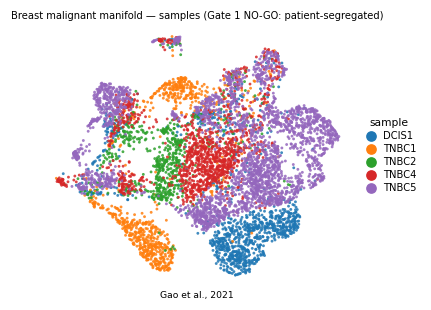

In [14]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=14, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=6.5, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold \u2014 samples (Gate 1 NO-GO: patient-segregated)', size=6.5)
ax.text(.5, -.06, 'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])